# Club draft record

One club's national draft picks (2005–2018) compared with the league-wide pick
curve from [notebook 01](01_draft_pick_value.ipynb).

**To use it:** set `CLUB` in the next cell to a DraftGuru club name (for example
`"Port Adelaide"`, `"GWS"`, `"Brisbane"`), then run all cells. Everything below,
including the summary text, is computed from the data.

The charts and tables come from `src/afl/draft_charts.py`.

In [1]:
CLUB = "Port Adelaide"

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from afl.draft_charts import (MAX_PICK, apply_style, club_benchmark, club_picks, draw_curve,
                              pick_curve, plot_club_benchmark, plot_club_picks)
from afl.draftguru import birth_dates, national_picks

FIRST_DRAFT, LAST_DRAFT = 2005, 2018
pd.set_option("display.width", 200)
apply_style()

picks = pd.concat([national_picks(year) for year in range(FIRST_DRAFT, LAST_DRAFT + 1)],
                  ignore_index=True)
picks = picks.merge(birth_dates(), on="draftguru_url", how="left")
picks["age_at_draft"] = (pd.to_datetime(picks["draft_year"].astype(str) + "-11-30")
                         - picks["dob"]).dt.days / 365.25

clubs_available = sorted(picks["club"].unique())
assert CLUB in clubs_available, f"Unknown club {CLUB!r}. Choose from: {clubs_available}"

curve = pick_curve(picks)
mine = club_picks(picks, curve, CLUB)
clubs = club_benchmark(picks, curve)

## Summary

In [3]:
row = clubs.loc[CLUB]
in_range = mine[mine["pick"] <= MAX_PICK]
league = picks[picks["pick"] <= MAX_PICK]

print(f"{CLUB}: {len(mine)} national draft picks, {FIRST_DRAFT}-{LAST_DRAFT}")
print(f"  Top 20: {(mine['pick'] <= 20).sum()}   picks 41+: {(mine['pick'] > 40).sum()}   "
      f"beyond pick {MAX_PICK} (left out of the benchmark): {(mine['pick'] > MAX_PICK).sum()}")
print(f"  Games vs expected (mean-based):   {row['vs_mean']:.2f}  "
      f"-> rank {int(row['rank_vs_mean'])} of {len(clubs)}")
print(f"  Games vs expected (median-based): {row['vs_median']:.2f}  "
      f"-> rank {int(row['rank_vs_median'])} of {len(clubs)}")
print(f"  Picks beating the median for their slot: {row['share_above_median']:.0%} "
      f"(about 50% is typical)")
print(f"  Share of draftees' games played for {CLUB}: {row['share_kept']:.0%} "
      f"(league range {clubs['share_kept'].min():.0%}-{clubs['share_kept'].max():.0%})")
print(f"  Mature-age picks (19+ at draft): {(in_range['age_at_draft'] >= 19).mean():.0%} "
      f"(league {(league['age_at_draft'] >= 19).mean():.0%})")

Port Adelaide: 59 national draft picks, 2005-2018
  Top 20: 14   picks 41+: 30   beyond pick 80 (left out of the benchmark): 3
  Games vs expected (mean-based):   1.12  -> rank 3 of 18
  Games vs expected (median-based): 1.55  -> rank 3 of 18
  Picks beating the median for their slot: 54% (about 50% is typical)
  Share of draftees' games played for Port Adelaide: 84% (league range 61%-90%)
  Mature-age picks (19+ at draft): 12% (league 15%)


## 1. The league-wide pick curve

This chart is the same for every club. Grey dots are individual picks, the line is
the median for picks within ±2, and the band is the middle 50%.

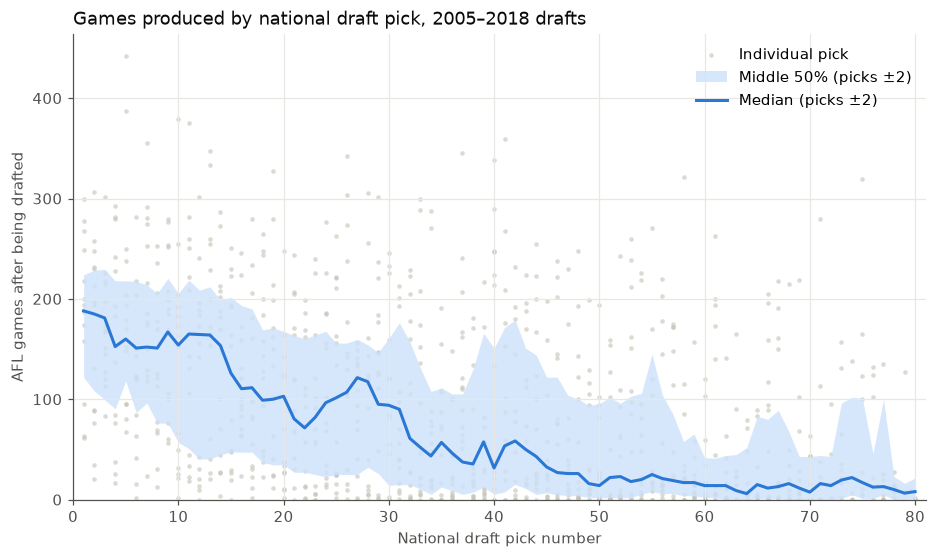

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
draw_curve(ax, picks, curve)
ax.set_title(f"Games produced by national draft pick, {FIRST_DRAFT}–{LAST_DRAFT} drafts",
             loc="left", color="#0b0b0b")
ax.legend(frameon=False, loc="upper right")
plt.show()

## 2. The club's picks against the curve

The labels mark the five picks furthest above the median for their slot, and
the three furthest below.

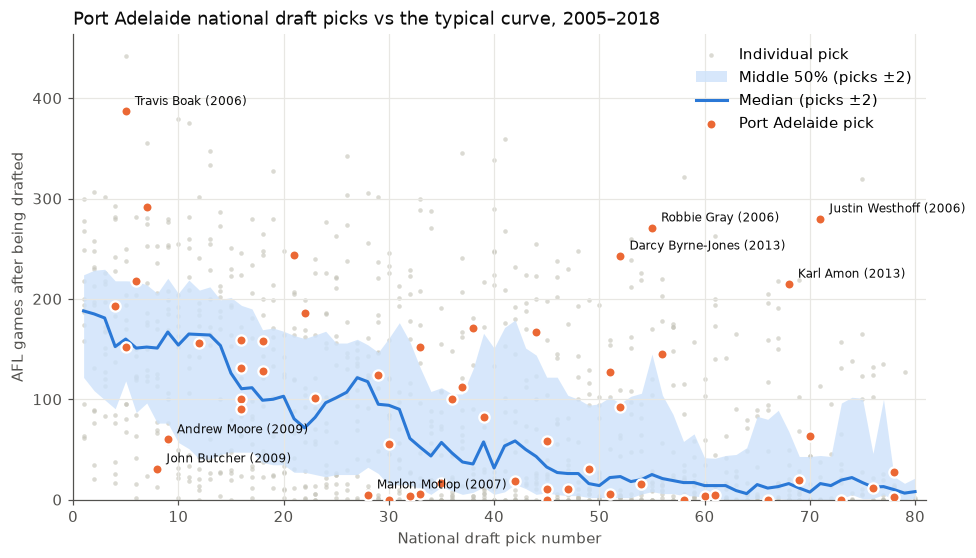

In [5]:
plot_club_picks(picks, curve, CLUB)
plt.show()

In [6]:
table = mine[["draft_year", "pick", "player", "signing", "age_at_draft", "height_cm",
              "games_after_draft", "games_for_drafting_club", "expected", "vs_expected"]]
table.rename(columns={"games_after_draft": "games", "games_for_drafting_club": f"games for {CLUB}",
                      "expected": "median at pick", "age_at_draft": "age"}).round(1)

,draft_year,pick,player,signing,age,height_cm,games,games for Port Adelaide,median at pick,vs_expected
29,2005,30,Nick Lower,,18.4,187.0,55,20,94.0,-39.0
43,2005,44,Alipate Carlile,,18.6,192.0,167,167,43.0,124.0
56,2005,58,Hugh Minson,,17.7,202.0,0,0,17.0,-17.0
64,2005,70,Jonathan Giles,,17.9,200.0,63,0,7.5,55.5
70,2006,5,Travis Boak,,18.3,183.0,387,387,160.0,227.0
88,2006,23,Paul Stewart,,19.4,191.0,101,101,82.0,19.0
104,2006,39,Nathan Krakouer,,18.6,182.0,82,69,57.5,24.5
120,2006,55,Robbie Gray,,18.7,183.0,271,271,25.0,246.0
135,2006,71,Justin Westhoff,,20.2,199.0,280,280,16.0,264.0
143,2006,83,Ryan Williams,,18.1,188.0,2,2,NaN,NaN


## 3. Every club on the mean-based benchmark

- **vs_mean**: total games divided by the sum of the mean at each pick (picks 1–80).
  This is the main measure.
- **vs_median**: shown for comparison. It flatters clubs that drafted late,
  because late picks are heavily skewed. See notebook 01.

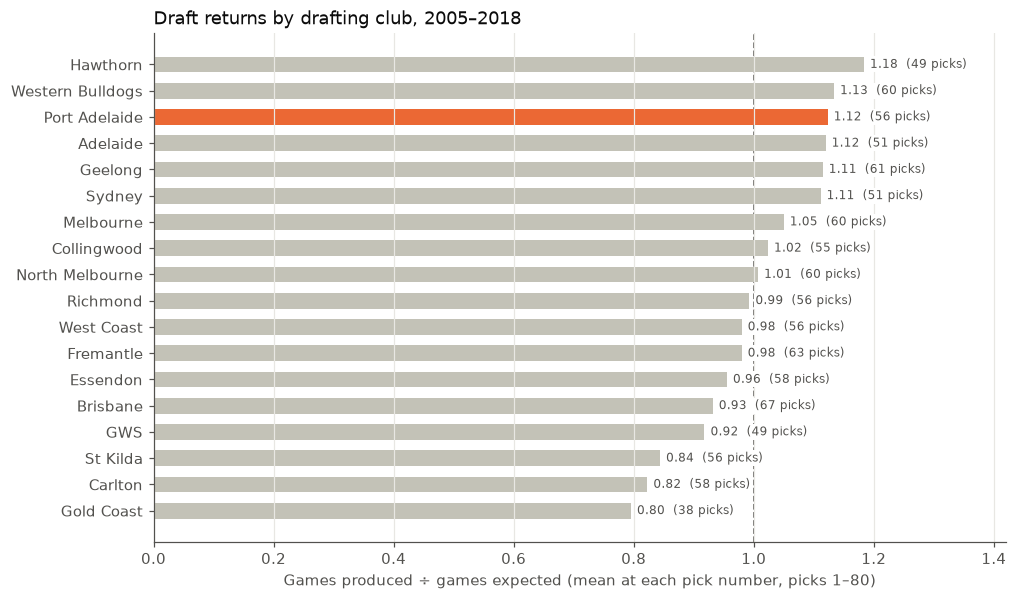

,picks,average_pick,vs_mean,rank_vs_mean,vs_median,rank_vs_median,share_above_median,share_kept
club,,,,,,,,
Hawthorn,49,41.43,1.18,1,1.77,1,0.51,0.74
Western Bulldogs,60,38.38,1.13,2,1.49,5,0.50,0.74
Port Adelaide,56,39.21,1.12,3,1.55,3,0.54,0.84
Adelaide,51,39.22,1.12,4,1.40,6,0.43,0.70
Geelong,61,42.89,1.11,5,1.69,2,0.54,0.74
Sydney,51,38.90,1.11,6,1.53,4,0.51,0.67
Melbourne,60,35.63,1.05,7,1.35,8,0.55,0.81
Collingwood,55,39.75,1.02,8,1.35,10,0.55,0.82
North Melbourne,60,38.65,1.01,9,1.35,9,0.50,0.90


In [7]:
plot_club_benchmark(clubs, CLUB, FIRST_DRAFT, LAST_DRAFT)
plt.show()

clubs[["picks", "average_pick", "vs_mean", "rank_vs_mean", "vs_median", "rank_vs_median",
       "share_above_median", "share_kept"]].round(2)

## Reading this carefully

- **Small samples.** A club has 40–70 picks here, and one or two drafts can
  dominate its result. Treat any ranking as a description, not a verdict on
  its recruiting.
- **Recruiting teams change.** These 14 drafts span several recruiting teams at
  every club.
- **Drafting isn't the same as keeping.** A good pick traded away still counts
  for the club that drafted him. "Share kept" shows how much of the value stayed.
- **Careers aren't finished.** Games run to the end of the latest season, so
  recent drafts are undercounted for every club alike.
- **Games are a proxy.** They don't measure quality or role.